# ECE 5831 – Assignment 05, Problem 1: Rock, Paper, Scissors with Teachable Machine

My own rock-paper-scissors script using a model I trained with Teachable Machine. It loads the trained model, takes a new image, runs forward propagation (inference), and classifies the image as Rock, Paper, or Scissors.

**How I made the model (as in the lecture demo)**
1. https://teachablemachine.withgoogle.com/ → *Image Project* → *Standard image model*
2. Make three classes, `Rock`, `Paper` and `Scissors`, and record a dataset for each class with the webcam
3. *Train Model*, then test it in the preview
4. *Export Model* → *Tensorflow* → *Keras* → *Download my model*. Unzip into `model/` so it contains `keras_model.h5` and `labels.txt`

**Environment (from the lecture)**
```
conda create -n tm_model python=3.10
conda activate tm_model
pip install tensorflow==2.15.0
pip install pillow numpy matplotlib
```
TensorFlow 2.15 loads the Teachable Machine `.h5` file directly. On newer TensorFlow (Keras 3) the loader below falls back to `tf_keras`.

**New test images** go in `test_images/`.

In [1]:
from pathlib import Path
import random

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

MODEL_DIR = Path("model")
TEST_DIR = Path("test_images")
IMG_SIZE = 224

## 1. Load the trained model and labels

Teachable Machine exports the model in the TensorFlow 2.15 (Keras 2) format. TensorFlow 2.16 and newer use Keras 3, which can't read this file. The next cell checks the TensorFlow version and, only if it's newer than 2.15, installs the matching `tf_keras` package (the Keras 2 version for that TensorFlow).

In [2]:
import importlib.util
import sys
import subprocess
import tensorflow as tf

major, minor = (int(v) for v in tf.__version__.split(".")[:2])
print("TensorFlow", tf.__version__)
if (major, minor) >= (2, 16) and importlib.util.find_spec("tf_keras") is None:
    pkg = f"tf-keras~={major}.{minor}.0"         # must match the TensorFlow version
    print("Installing", pkg, "...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
    importlib.invalidate_caches()
    print("Done")

TensorFlow 2.21.0
Installing tf-keras~=2.21.0 ...
Done


In [3]:
def load_keras_model(h5_path):
    """Try the Keras bundled with TensorFlow first, then the legacy tf_keras package."""
    errors = []
    for module in ("tensorflow.keras", "tf_keras"):
        try:
            if module == "tensorflow.keras":
                from tensorflow import keras
            else:
                import tf_keras as keras
            m = keras.models.load_model(h5_path, compile=False)
            print(f"Loaded {h5_path} with {module}")
            return m
        except Exception as e:
            errors.append(f"{module}: {type(e).__name__}: {e}")
    raise RuntimeError("Could not load model:\n" + "\n".join(errors))


def read_labels(path):
    # each line is "<index> <name>", e.g. "0 Rock"
    labels = {}
    for line in Path(path).read_text().splitlines():
        if line.strip():
            idx, name = line.strip().split(maxsplit=1)
            labels[int(idx)] = name
    return [labels[i] for i in sorted(labels)]


model = load_keras_model(MODEL_DIR / "keras_model.h5")
labels = read_labels(MODEL_DIR / "labels.txt")
print("Classes:", labels)
print("Input shape:", model.input_shape, " Output shape:", model.output_shape)




Loaded model\keras_model.h5 with tf_keras
Classes: ['Paper', 'Scissor', 'Rock']
Input shape: (None, 224, 224, 3)  Output shape: (None, 3)


## 2. Pre-processing + forward propagation

Teachable Machine expects exactly what it saw during training:
- RGB, resized and **center-cropped** to 224×224
- pixel values normalised from [0, 255] to **[-1, 1]**: `x / 127.5 - 1`
- a batch dimension → shape `(1, 224, 224, 3)`

Calling the model on that tensor runs the forward pass through every layer (MobileNet feature extractor + dense head) and the last softmax gives one probability per class.

In [4]:
class RPSClassifier:
    def __init__(self, model, labels, size=IMG_SIZE):
        self.model, self.labels, self.size = model, labels, size

    def prepare(self, image_path):
        img = Image.open(image_path)
        img = ImageOps.exif_transpose(img).convert("RGB")      # respect phone photo rotation
        img = ImageOps.fit(img, (self.size, self.size), method=Image.Resampling.LANCZOS)
        x = np.asarray(img, dtype=np.float32) / 127.5 - 1.0
        return img, np.expand_dims(x, axis=0)

    def forward(self, batch):
        out = self.model(batch, training=False)              # forward propagation
        return np.asarray(out)[0]

    def classify(self, image_path, show=True):
        img, batch = self.prepare(image_path)
        probs = self.forward(batch)
        k = int(np.argmax(probs))
        if show:
            self.show(img, probs, Path(image_path).name)
        return self.labels[k], float(probs[k]), probs

    def show(self, img, probs, title):
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(7, 3), gridspec_kw={"width_ratios": [1, 1.3]})
        a1.imshow(img); a1.axis("off"); a1.set_title(title, fontsize=9)
        colors = ["tab:green" if i == np.argmax(probs) else "lightgray" for i in range(len(probs))]
        a2.barh(self.labels, probs, color=colors)
        a2.set_xlim(0, 1); a2.invert_yaxis(); a2.set_xlabel("probability")
        for i, p in enumerate(probs):
            a2.text(min(p + 0.02, 0.85), i, f"{p:.1%}", va="center", fontsize=8)
        plt.tight_layout(); plt.show()


clf = RPSClassifier(model, labels)

## 3. Classify a new image

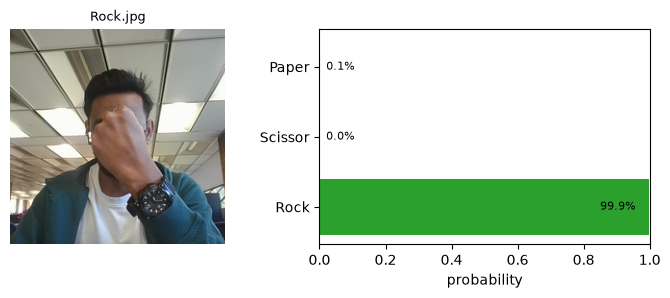

Prediction: Rock  (confidence 99.9%)


In [5]:
label, conf, probs = clf.classify(TEST_DIR / "Rock.jpg")       # <- change to any new image
print(f"Prediction: {label}  (confidence {conf:.1%})")

## 4. Classify every image in `test_images/`

In [6]:
exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
for p in sorted(TEST_DIR.iterdir()):
    if p.suffix.lower() in exts:
        label, conf, _ = clf.classify(p, show=False)
        print(f"{p.name:25s} -> {label:9s} {conf:.1%}")

Paper.jpg                 -> Paper     88.9%
Rock.jpg                  -> Rock      99.9%
Scissor.jpg               -> Rock      49.0%


## 5. Bonus: play a round against the computer
My hand comes from the classifier, the computer picks at random.

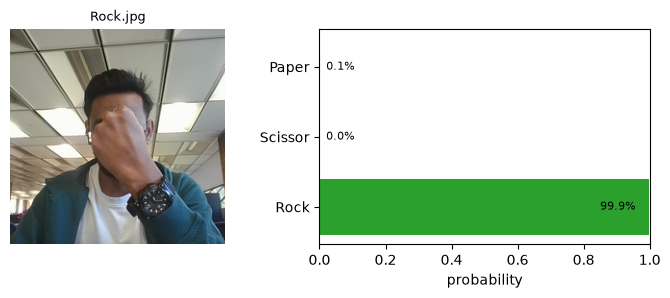

You: rock (100%)   Computer: scissors
You win!


In [7]:
BEATS = {"rock": "scissors", "paper": "rock", "scissors": "paper"}


def to_move(label):
    # Teachable Machine class names can be "Scissor", "Scissors", "rock" ... -> one spelling
    name = label.strip().lower()
    return "scissors" if name.startswith("scissor") else name


def play(image_path, seed=None):
    rng = random.Random(seed)
    label, conf, _ = clf.classify(image_path)
    me = to_move(label)
    cpu = rng.choice(list(BEATS))
    print(f"You: {me} ({conf:.0%})   Computer: {cpu}")
    if me not in BEATS:
        print("Unknown gesture")
    elif me == cpu:
        print("Draw!")
    elif BEATS[me] == cpu:
        print("You win!")
    else:
        print("Computer wins!")


play(TEST_DIR / "Rock.jpg")

## 6. Results

| Test image | Prediction | Probability (Paper / Scissor / Rock) |
|---|---|---|
| `Paper.jpg` | **Paper** ✔ | 0.889 / 0.066 / 0.045 |
| `Rock.jpg` | **Rock** ✔ | 0.001 / 0.000 / 0.999 |
| `Scissor.jpg` | Rock ✘ | 0.100 / 0.410 / 0.490 |

Paper and Rock were classified correctly with high confidence. The scissors photo was a near miss: Scissor was a close second at 41% against 49% for Rock. In that photo my two fingers point sideways across my face instead of up, and much of the hand is the closed part, which looks like a fist. More scissors samples at different angles in Teachable Machine would make the model more robust to this.